In [92]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from scipy.io import loadmat



Exercise 1
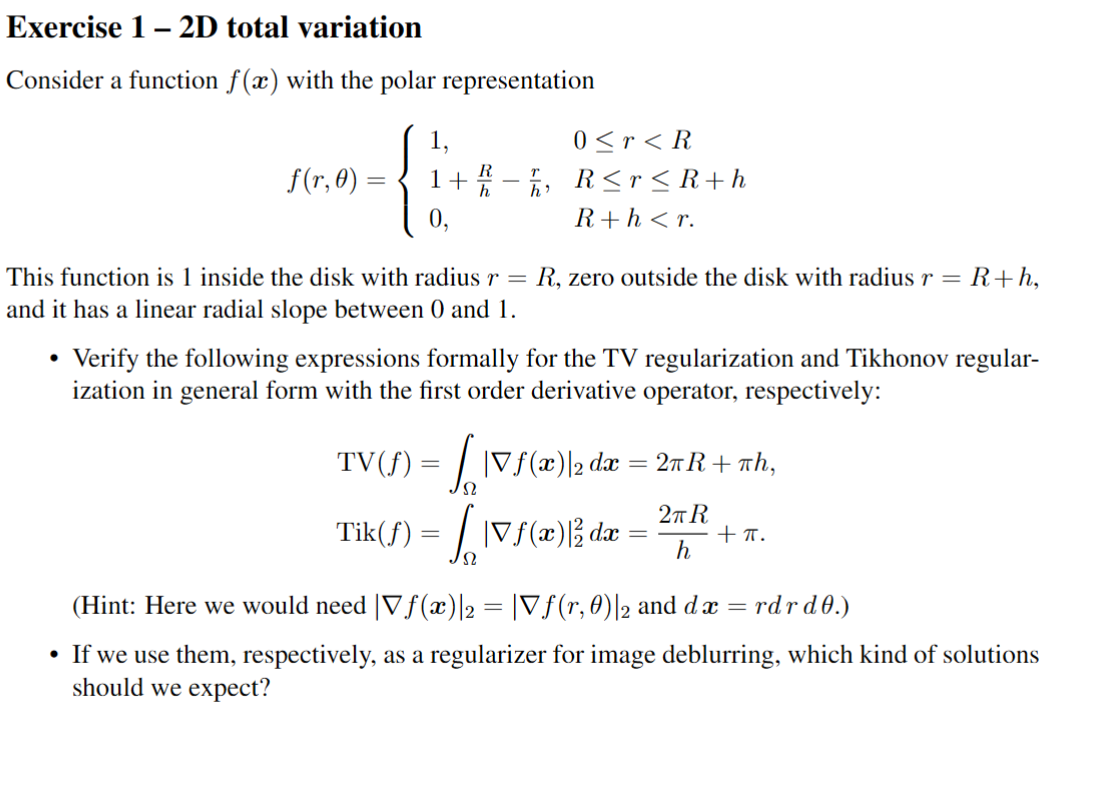

See paper notebook

# Exercise 2
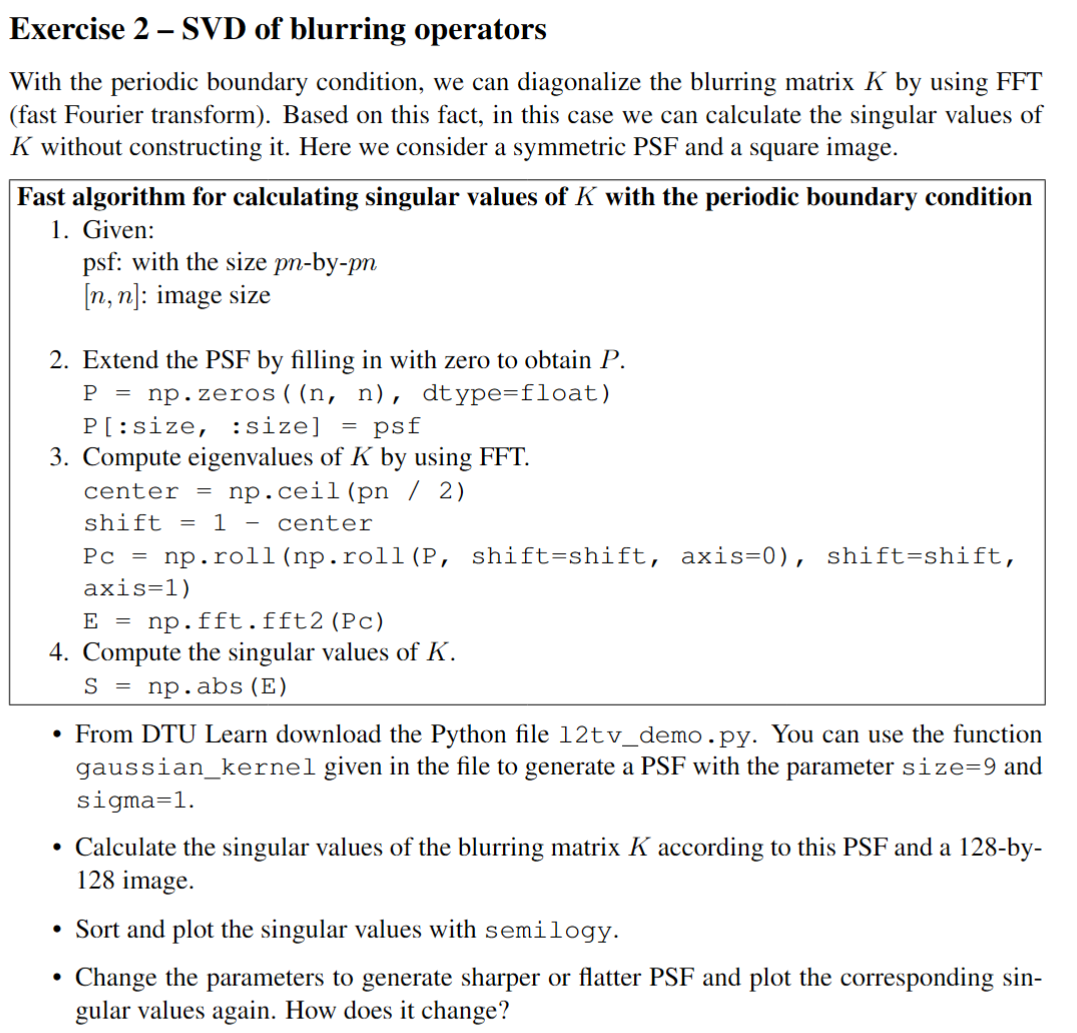

In [93]:
# From 12tv_demo.py
def gaussian_kernel(size, sigma):
    assert size % 2 == 1, "Kernel size must be odd."
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax, indexing='xy')
    ker = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    ker /= ker.sum()
    return ker


Text(0.5, 1.0, 'Sorted Singular Values')

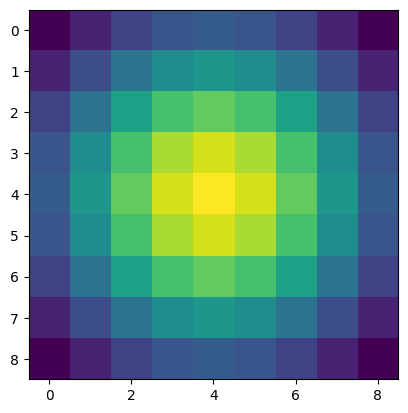

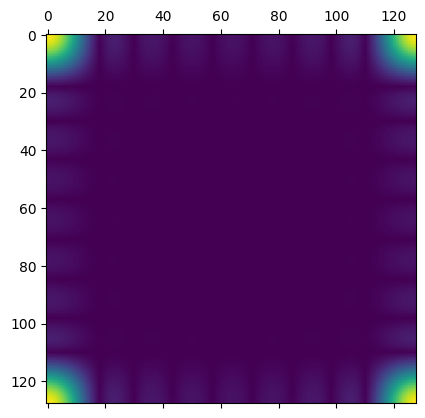

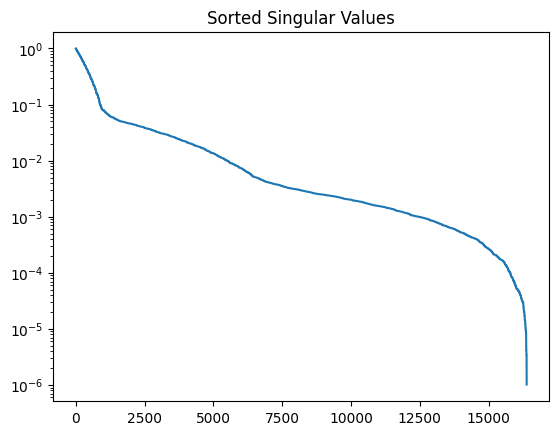

In [94]:
size = 9
sigma = 3.0
psf = gaussian_kernel(size=size, sigma=sigma)

plt.figure()
plt.imshow(psf)


n = 128

# Pad PSF to obtain P
P = np.zeros((n, n), dtype=np.float64)
P[:size, :size] = psf
plt.figure()
plt.spy(P)

# Compute eigenvalues
center = np.ceil(size / 2)
shift = 1 - center
Pc = np.roll(np.roll(P, shift=shift, axis=0), shift=shift, axis=1)
E = np.fft.fft2(Pc)
S = np.abs(E)
S
plt.imshow(S)

plt.figure()
plt.semilogy(np.sort(S.flatten())[::-1])
plt.title("Sorted Singular Values")

Increasing sigma, i.e. flatter PSF gives rise to a flatter spectrum of singular values

Decreasing sigma, i.e. a sharper PSF gives an almost linearly decreasing curve for the singular values

# Exercise 3
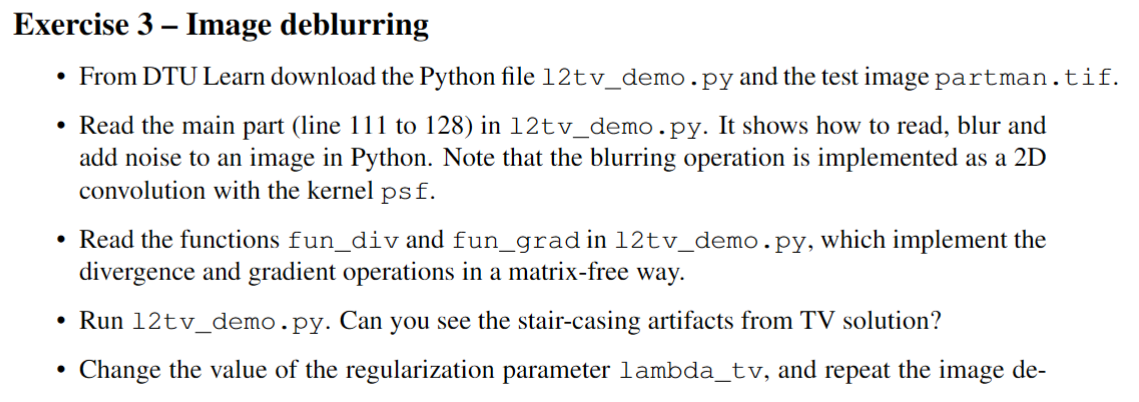
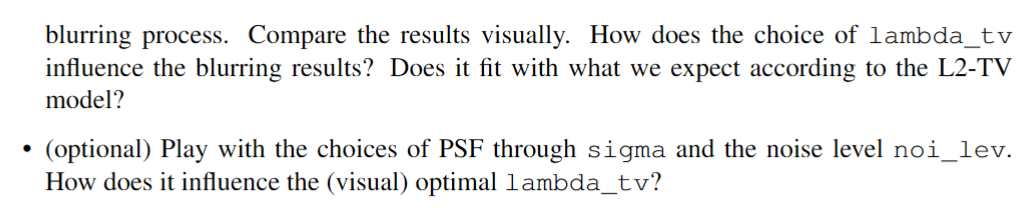

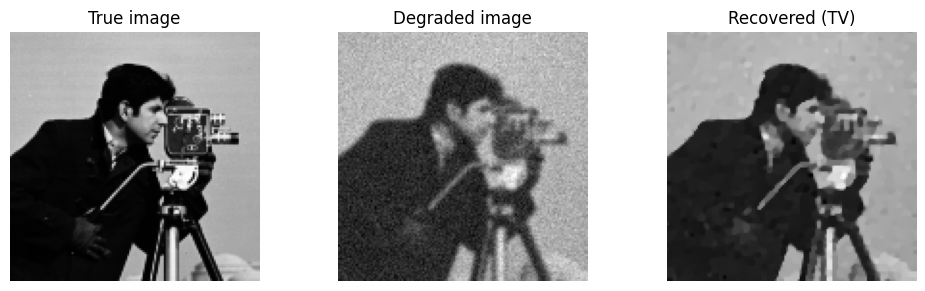

In [95]:
def gaussian_kernel(size, sigma):
    assert size % 2 == 1, "Kernel size must be odd."
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax, indexing='xy')
    ker = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    ker /= ker.sum()
    return ker


def fun_grad(u):
    """
    The gradient of u in forward difference scheme with symmetric boundary condition
    """
    m1, m2 = u.shape
    gradx = np.concatenate([np.diff(u, axis=1), np.zeros((m1, 1), dtype=u.dtype)], axis=1)
    grady = np.concatenate([np.diff(u, axis=0), np.zeros((1, m2), dtype=u.dtype)], axis=0)
    return gradx, grady


def fun_div(v1, v2):
    """
    The divergence operation that is the adjoint of the above gradient operation.
    """
    # Horizontal component
    div_v1 = np.hstack([
        v1[:, [0]],
        v1[:, 1:-1] - v1[:, :-2],
        -v1[:, [-2]]
    ])
    # Vertical component
    div_v2 = np.vstack([
        v2[[0], :],
        v2[1:-1, :] - v2[:-2, :],
        -v2[[-2], :]
    ])
    return div_v1 + div_v2


def tv_deconv_primal_dual(f, psf, lam, maxits=500, L2=8.0):
    """
    Primal-dual (PDHG / Chambolle-Pock) TV-regularized deconvolution.

    Parameters
    ----------
    f : (M, N) ndarray
        Observed blurry/noisy image.
    psf : (kh, kw) ndarray
        Point spread function (assumed odd-sized for symmetry).
    lam : float
        Regularization weight (lambda).
    maxits : int
        Number of iterations.
    L2 : float
        Lipschitz parameter used to set sigma, tau = 1/sqrt(L2).

    Returns
    -------
    u : (M, N) ndarray
        Recovered image after `maxits` iterations.
    """


    if np.ndim(psf) >= 2:
        psf_ad = np.rot90(psf, 2) # adjoint psf
    else:
        psf_ad = psf

    M, N = f.shape
    u = np.zeros((M, N), dtype=np.float64)
    u_ = u.copy()
    v = np.zeros((M, N), dtype=np.float64)
    px = np.zeros((M, N), dtype=np.float64)
    py = np.zeros((M, N), dtype=np.float64)

    # Step sizes
    sigma = 1.0 / np.sqrt(L2)

    for k in range(maxits):
        # --- ascend step for v ---
        Au_ = convolve2d(u_, psf, mode='same', boundary='symm')
        v = v + sigma * (Au_ - f)

        # Prox for the quadratic term (I + sigma*lam)^{-1}
        v = v / (1.0 + sigma * lam)


        # --- ascend step for p = (px, py) ---
        ux, uy = fun_grad(u_)
        px = px + sigma * ux
        py = py + sigma * uy

        # Prox onto the l2 unit ball (isotropic TV dual constraint)
        pabsm = np.maximum(1.0, np.sqrt(px**2 + py**2))
        px /= pabsm
        py /= pabsm

        # --- descend step for u ---
        uold = u.copy()
        adjoint = convolve2d(v, psf_ad, mode='same', boundary='symm')
        div_p = fun_div(px, py)
        u = u - sigma * (adjoint - div_p)

        # --- leading point (over-relaxation) ---
        u_ = 2.0 * u - uold

    return u


# Load the images.
here = Path().resolve()
u_org = plt.imread(here / "partman.tif")
u_org = u_org/255
rows, cols = u_org.shape


# generate a gaussian blurring psf
psf_size = 9
sigma = 1.0
psf = gaussian_kernel(psf_size, sigma)


# perform blurring
u0 = convolve2d(u_org, psf, mode='same', boundary='symm')

# add gaussian noise
noi_lev = 0.05
u_noise = u0 + noi_lev * np.random.randn(*u0.shape)


# deblur by solving L2-TV model
lambda_tv = 0.01
u_tv = tv_deconv_primal_dual(u_noise, psf, lambda_tv)


# show the results
plt.figure(figsize=(10, 3))
plt.subplot(1, 3, 1)
plt.imshow(u_org, cmap='gray')
plt.title("True image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(u_noise, cmap='gray')
plt.title("Degraded image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(u_tv, cmap='gray')
plt.title("Recovered (TV)")
plt.axis('off')

plt.tight_layout()
plt.show()


Increasing $λ$ coarsens the staircasing levels as we would expect.

Lowering it increases the number of staircasing levels, making the image capture more details of the original, but at the cost of increased noise.

For noise level 0.05, I reckon lambda 0.01 is a decent choice 

# Exercise 4
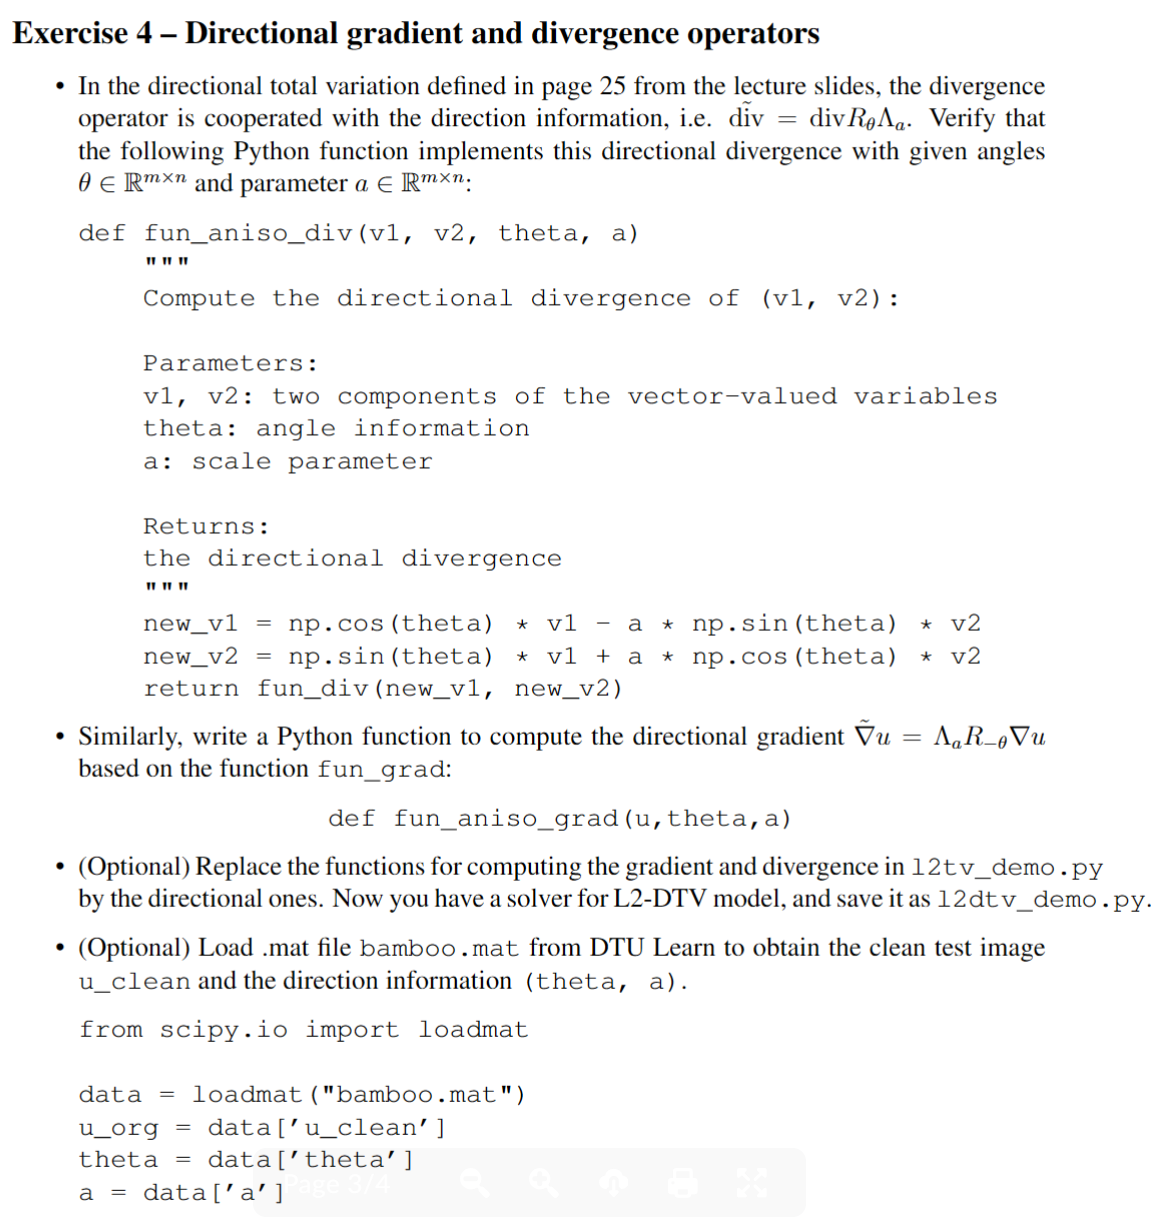
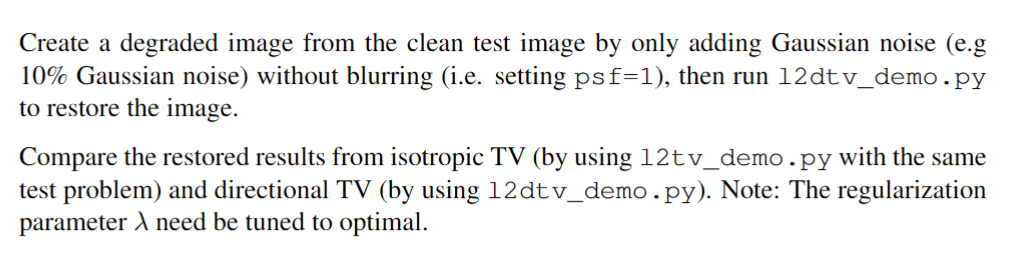

In [96]:
def fun_aniso_div(v1, v2, theta, a):
    """
    Compute the directional divergence of (v1, v2):

    Parameters:
        v1, v2: two components of the vector-valued variables
        theta: angle information
        a: scale parameter
    Returns:
        the directional divergence
    """
    new_v1 = np.cos(theta) * v1 - a * np.sin(theta) * v2
    new_v2 = np.sin(theta) * v1 + a * np.cos(theta) * v2
    return fun_div(new_v1, new_v2)

Clearly, `fun_aniso_div` does the required rotation and scaling prior to computing the divergence. 

In [106]:
def fun_aniso_grad(u, theta, a):
    """
    Compute the directional gradient of u:

    Parameters:
        u: input image
        theta: angle information
        a: scale parameter

    Returns:
        two components of the directional gradient
    """
    ux, uy = fun_grad(u)
    new_ux =  np.cos(theta) * ux + np.sin(theta) * uy
    new_uy = a * (-np.sin(theta) * ux + np.cos(theta) * uy)
    return new_ux, new_uy


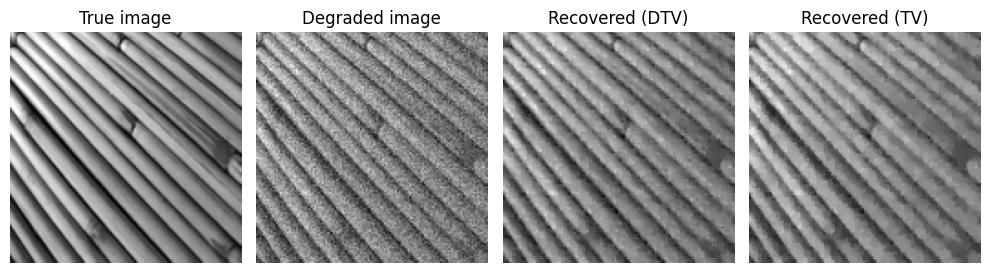

In [ ]:
def gaussian_kernel(size, sigma):
    assert size % 2 == 1, "Kernel size must be odd."
    ax = np.arange(-size // 2 + 1., size // 2 + 1.)
    xx, yy = np.meshgrid(ax, ax, indexing='xy')
    ker = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    ker /= ker.sum()
    return ker

def dtv_deconv_primal_dual(f, psf, lam, theta, a, maxits=500, L2=8.0):
    """
    Primal-dual (PDHG / Chambolle-Pock) TV-regularized deconvolution.

    Parameters
    ----------
    f : (M, N) ndarray
        Observed blurry/noisy image.
    psf : (kh, kw) ndarray
        Point spread function (assumed odd-sized for symmetry).
    lam : float
        Regularization weight (lambda).
    maxits : int
        Number of iterations.
    L2 : float
        Lipschitz parameter used to set sigma, tau = 1/sqrt(L2).

    Returns
    -------
    u : (M, N) ndarray
        Recovered image after `maxits` iterations.
    """


    if np.ndim(psf) >= 2:
        psf_ad = np.rot90(psf, 2) # adjoint psf
    else:
        psf_ad = psf

    M, N = f.shape
    u = np.zeros((M, N), dtype=np.float64)
    u_ = u.copy()
    v = np.zeros((M, N), dtype=np.float64)
    px = np.zeros((M, N), dtype=np.float64)
    py = np.zeros((M, N), dtype=np.float64)

    # Step sizes
    sigma = 1.0 / np.sqrt(L2)

    for k in range(maxits):
        # --- ascend step for v ---
        Au_ = convolve2d(u_, psf, mode='same', boundary='symm')
        v = v + sigma * (Au_ - f)

        # Prox for the quadratic term (I + sigma*lam)^{-1}
        v = v / (1.0 + sigma * lam)


        # --- ascend step for p = (px, py) ---
        ux, uy = fun_aniso_grad(u_, theta, a)
        px = px + sigma * ux
        py = py + sigma * uy

        # Prox onto the l2 unit ball (isotropic TV dual constraint)
        pabsm = np.maximum(1.0, np.sqrt(px**2 + py**2))
        px /= pabsm
        py /= pabsm

        # --- descend step for u ---
        uold = u.copy()
        adjoint = convolve2d(v, psf_ad, mode='same', boundary='symm')
        div_p = fun_aniso_div(px, py, theta, a)
        u = u - sigma * (adjoint - div_p)

        # --- leading point (over-relaxation) ---
        u_ = 2.0 * u - uold

    return u

# Load the images.
data = loadmat("bamboo.mat")
u_org = data["u_clean"]
theta = data["theta"]
a = data["a"]

# generate a gaussian blurring psf
psf_size = 1
sigma = 1.0
psf = gaussian_kernel(psf_size, sigma)

# perform blurring
u0 = convolve2d(u_org, psf, mode='same', boundary='symm')

# add gaussian noise
noi_lev = 0.10
u_noise = u0 + noi_lev * np.random.randn(*u0.shape)

# deblur by solving L2-TV model
lambda_dtv = 0.08
u_dtv = dtv_deconv_primal_dual(u_noise, psf, lambda_dtv, theta, a)
lambda_tv = 0.08
u_tv = tv_deconv_primal_dual(u_noise, psf, lambda_tv)
# show the results
plt.figure(figsize=(10, 3))
plt.subplot(1, 4, 1)
plt.imshow(u_org, cmap='gray')
plt.title("True image")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(u_noise, cmap='gray')
plt.title("Degraded image")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(u_dtv, cmap='gray')
plt.title("Recovered (DTV)")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(u_tv, cmap='gray')
plt.title("Recovered (TV)")
plt.axis('off')

plt.tight_layout()
plt.show()


We note that due to the anisotropy we are able to use our prior knowledge of the characteristic directions of the image to improve our solution further